# 大模型微调 09：BERT + PET 模型训练与推理

本篇对应 `09-笔记/03-BERT+PET方式模型代码实现与训练.pdf` 和 `09-代码/PET`。上一篇已经完成 PET 的任务改写、HardTemplate、数据预处理和小样本分类思路；本篇把这些组件接起来，完成 BERT+PET 的工具类、训练、验证、最佳模型保存和推理。

## 学习目标

- 理解 Verbalizer 如何在主标签和子标签之间建立双向映射；
- 理解 `[MASK]` 位置的 MLM loss 如何替代普通分类头的交叉熵；
- 能读懂训练循环、学习率调度、验证和 `model_best` 保存逻辑；
- 能复用同一 Prompt、模板和 Verbalizer 完成批量推理；
- 能根据日志和每类指标判断小样本训练的效果与局限。

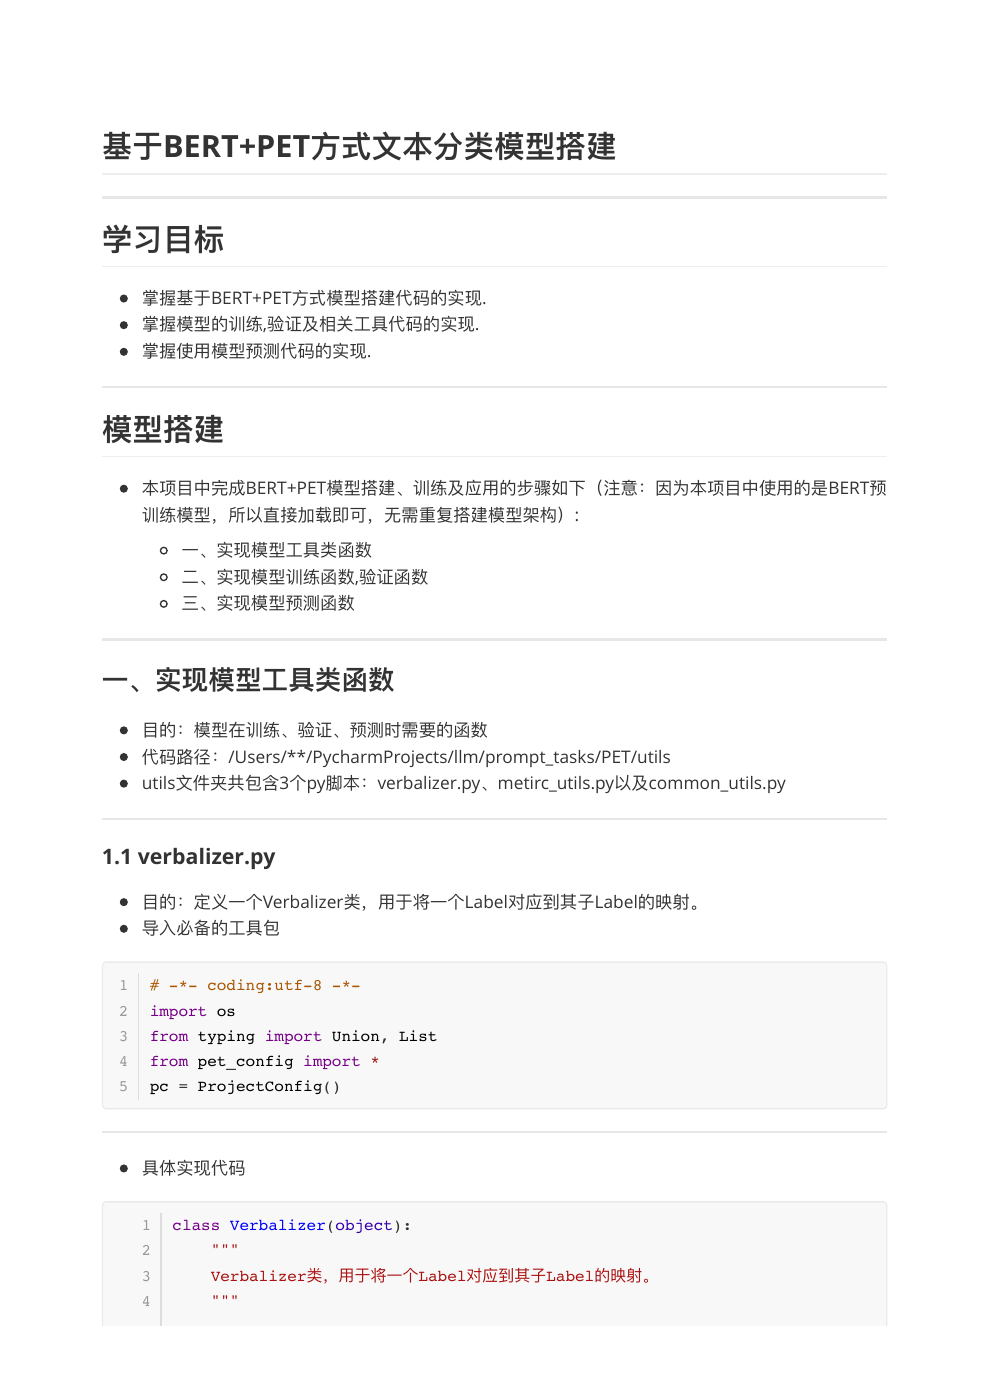

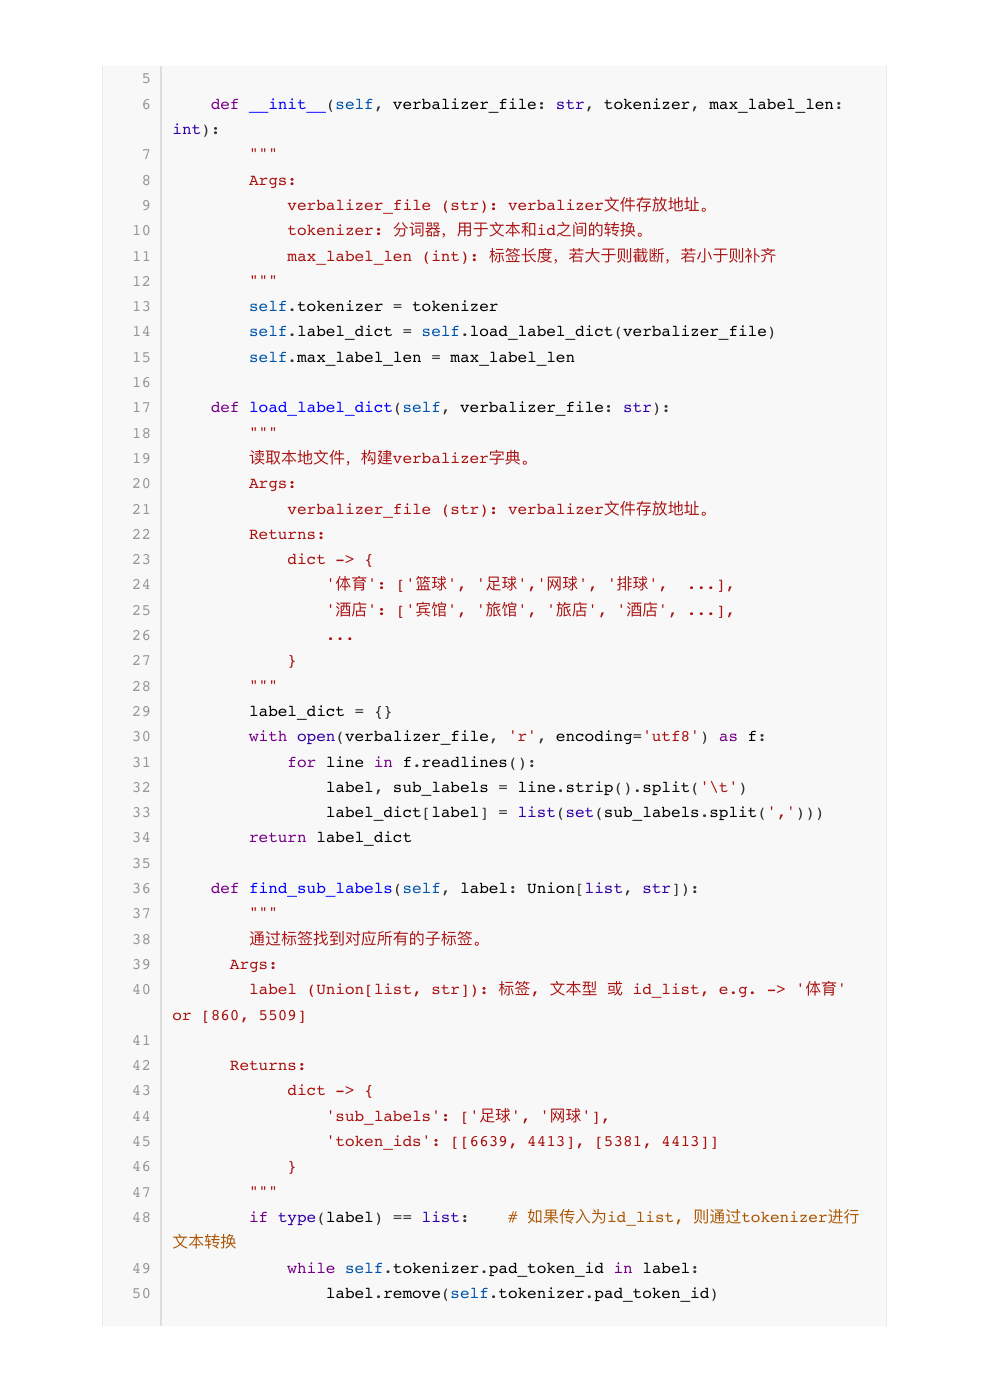

## 一、完整实现的模块关系

资料中的实现不再重新搭建 BERT，而是直接加载 `AutoModelForMaskedLM`。数据和模型之间的调用链如下：

```text
原始文本 + label
    ↓
HardTemplate / convert_example
    ↓  input_ids、attention_mask、mask_positions、mask_labels
BertForMaskedLM
    ↓  (batch, seq_len, vocab_size) logits
只取 [MASK] 位置 → convert_logits_to_ids / mlm_loss
    ↓
Verbalizer：子标签 token ↔ 主标签
    ↓
ClassEvaluator：accuracy、precision、recall、F1、每类指标
```

训练时只在 `[MASK]` 位置计算损失；验证和推理时从这些位置取出预测 token，再通过 Verbalizer 还原成业务类别。这样分类任务使用的是 BERT 已经具备的 MLM 词汇预测能力。

## 二、项目配置、Prompt 与 Verbalizer

配置类集中保存模型路径、数据路径、训练超参数和设备。资料中的默认配置是：`max_seq_len=256`、`batch_size=8`、`learning_rate=5e-5`、`warmup_ratio=0.06`、`max_label_len=2`、`epochs=20`、每 2 步打印日志、每 20 步验证一次。示例代码使用 MPS；在 Windows 上应按实际环境改为 `cuda:0` 或 `cpu`。

Prompt 文件内容为：`这是一条{MASK}评论：{textA}。`。本资料的 `verbalizer.txt` 为一对一映射，例如 `电脑	电脑`、`酒店	酒店`、`水果	水果`。如果一个主标签对应多个自然词，可以写成 `水果	苹果,香蕉,橘子`，训练时会对这些子标签都计算候选损失。

```python
# coding:utf-8
import torch
import sys
# print(sys.path)


class ProjectConfig(object):
    def __init__(self):
        # self.device = 'cuda:0' if torch.cuda.is_available() else 'cpu' # windows电脑/linux服务器
        self.device = "mps:0" # MAC电脑
        self.pre_model = '/Users/ligang/PycharmProjects/LLM/prompt_tasks/bert-base-chinese'
        self.train_path = '/Users/ligang/PycharmProjects/LLM/prompt_tasks/PET/data/train.txt'
        self.dev_path = '/Users/ligang/PycharmProjects/LLM/prompt_tasks/PET/data/dev.txt'
        self.prompt_file = '/Users/ligang/PycharmProjects/LLM/prompt_tasks/PET/data/prompt.txt'
        self.verbalizer = '/Users/ligang/PycharmProjects/LLM/prompt_tasks/PET/data/verbalizer.txt'
        self.max_seq_len = 256
        self.batch_size = 8
        self.learning_rate = 5e-5
        self.weight_decay = 0
        self.warmup_ratio = 0.06
        self.max_label_len = 2
        self.epochs = 20
        self.logging_steps = 2
        self.valid_steps = 20
        self.save_dir = '/Users/ligang/PycharmProjects/LLM/prompt_tasks/PET/checkpoints'


if __name__ == '__main__':
    pc = ProjectConfig()
    print(pc.prompt_file)
    print(pc.pre_model)

```

### 配置检查清单

1. `pre_model` 必须指向包含 BERT tokenizer 和权重的目录；
2. `train_path`、`dev_path`、`prompt_file`、`verbalizer` 要与当前工程位置一致；
3. `device` 必须与本机 PyTorch 支持的设备一致；
4. `max_label_len` 至少覆盖最长子标签的 token 长度；
5. `save_dir` 需要有写权限，验证时才可以保存 `model_best`。

## 三、Verbalizer：主标签与子标签的双向转换

`Verbalizer` 读取每行的 `主标签	子标签1,子标签2,...`，构建 `label_dict`。它提供两条关键路径：

- `find_sub_labels()`：训练时把主标签转为多个子标签，并 tokenize、截断或补 `[PAD]` 到固定长度；
- `find_main_label()`：验证/推理时把模型输出的 token ID 转为子标签，再找到对应主标签。

当模型生成的子标签不在字典中时，`hard_mapping()` 会用最大公共子串长度做近似归类。这是工程上的兜底策略，不能替代更完整的标签词表；标签词越短或越相似，误映射风险越高。

```python
# -*- coding:utf-8 -*-
import os
from typing import Union, List
# Union 是 typing 模块中定义的一个类,用于表示多个类型中的任意一种类型
from pet_config import *
pc = ProjectConfig()

class Verbalizer(object):
    """
    Verbalizer类，用于将一个Label对应到其子Label的映射。
    """

    def __init__(self, verbalizer_file: str, tokenizer, max_label_len: int):
        """
        Args:
            verbalizer_file (str): verbalizer文件存放地址。
            tokenizer: 用于文本和id之间的转换。
            max_label_len (int): 标签长度，若大于则截断，若小于则补齐
        """
        self.tokenizer = tokenizer
        self.label_dict = self.load_label_dict(verbalizer_file)
        self.max_label_len = max_label_len

    def load_label_dict(self, verbalizer_file: str):
        """
        读取本地文件，构建verbalizer字典。

        Args:
            verbalizer_file (str): verbalizer文件存放地址。

        Returns:
            dict -> {
                '体育': ['篮球', '足球','网球', '排球',  ...],
                '酒店': ['宾馆', '旅馆', '旅店', '酒店', ...],
                ...
            }
        """
        label_dict = {}
        with open(verbalizer_file, 'r', encoding='utf8') as f:
            for line in f.readlines():
                # print(f'line-->{line}')
                label, sub_labels = line.strip().split('\t')
                label_dict[label] = list(set(sub_labels.split(',')))

        return label_dict
    
    def find_sub_labels(self, label: Union[list, str]):
        """
        通过主标签找到所有的子标签。

        Args:
            label (Union[list, str]): 标签, 文本型 或 id_list, e.g. -> '体育' or [860, 5509]
        
        Returns:
            dict -> {
                'sub_labels': ['足球', '网球'],
                'token_ids': [[6639, 4413], [5381, 4413]]
            }
        """
        if type(label) == list:                                                 # 如果传入为id_list, 则通过tokenizer转回来
            while self.tokenizer.pad_token_id in label:
                label.remove(self.tokenizer.pad_token_id)
            label = ''.join(self.tokenizer.convert_ids_to_tokens(label))
        # print(f'label-->{label}')
        if label not in self.label_dict:
            raise ValueError(f'Lable Error: "{label}" not in label_dict {list(self.label_dict)}.')
        
        sub_labels = self.label_dict[label]
        # print(f'sub_labels-->{sub_labels}')
        ret = {'sub_labels': sub_labels}
        # print(f"self.tokenizer(sub_labels)-->{self.tokenizer(sub_labels)}")
        token_ids = [_id[1:-1] for _id in self.tokenizer(sub_labels)['input_ids']]
        # print(f'token_ids-->{token_ids}')
        for i in range(len(token_ids)):
            token_ids[i] = token_ids[i][:self.max_label_len]                    # 对标签进行截断与补齐
            if len(token_ids[i]) < self.max_label_len:
                token_ids[i] = token_ids[i] + [self.tokenizer.pad_token_id] * (self.max_label_len - len(token_ids[i]))
        ret['token_ids'] = token_ids
        return ret
    
    def batch_find_sub_labels(self, label: List[Union[list, str]]):
        """
        批量找到子标签。

        Args:
            label (List[list, str]): 标签列表, [[4510, 5554], [860, 5509]] or ['体育', '电脑']

        Returns:
            list -> [
                        {
                            'sub_labels': ['笔记本', '电脑'], 
                            'token_ids': [[5011, 6381, 3315], [4510, 5554]]
                        },
                        ...
                    ]
        """
        return [self.find_sub_labels(l) for l in label]

    def get_common_sub_str(self, str1: str, str2: str):
        """
        寻找最大公共子串(连续子序列)。
        str1:abcd
        str2:abadbcdba
        """
        lstr1, lstr2 = len(str1), len(str2)
        # 生成0矩阵，为方便后续计算，比字符串长度多了一列
        record = [[0 for i in range(lstr2 + 1)] for j in range(lstr1 + 1)]
        p = 0  # 最长匹配对应在str1中的最后一位
        maxNum = 0  # 最长匹配长度

        for i in range(lstr1):
            for j in range(lstr2):
                if str1[i] == str2[j]:
                    record[i+1][j+1] = record[i][j] + 1
                    if record[i+1][j+1] > maxNum:
                        maxNum = record[i+1][j+1]
                        p = i + 1

        return str1[p-maxNum:p], maxNum

    def hard_mapping(self, sub_label: str):
        """
        强匹配函数，当模型生成的子label不存在时，通过最大公共子串找到重合度最高的主label。

        Args:
            sub_label (str): 子label。

        Returns:
            str: 主label。
        """
        label, max_overlap_str = '', 0
        # print(self.label_dict.items())
        for main_label, sub_labels in self.label_dict.items():
            overlap_num = 0
            for s_label in sub_labels:                                  # 求所有子label与当前推理label之间的最长公共子串长度
                # print(f'self.get_common_sub_str(sub_label, s_label)-->{self.get_common_sub_str(sub_label, s_label)}')
                overlap_num += self.get_common_sub_str(sub_label, s_label)[1]
            # print(f'main_label, sub_labels, overlap_num--》{main_label, sub_labels, overlap_num}')
            if overlap_num >= max_overlap_str:
                max_overlap_str = overlap_num
                label = main_label

        return label

    def find_main_label(self, sub_label: Union[list, str], hard_mapping=True):
        """
        通过子标签找到父标签。

        Args:
            sub_label (Union[list, str]): 子标签, 文本型 或 id_list, e.g. -> '苹果' or [5741, 3362]
            hard_mapping (bool): 当生成的词语不存在时，是否一定要匹配到一个最相似的label。

        Returns:
            dict -> {
                'label': '水果', 
                'token_ids': [3717, 3362]
            }
        """
        if type(sub_label) == list:                                    # 如果传入为id_list, 则通过tokenizer转回来
            pad_token_id = self.tokenizer.pad_token_id
            while pad_token_id in sub_label:                           # 移除[PAD]token
                sub_label.remove(pad_token_id)
            sub_label = ''.join(self.tokenizer.convert_ids_to_tokens(sub_label))
        # print(f'sub_label-->{sub_label}')
        main_label = '无'
        for label, s_labels in self.label_dict.items():
            if sub_label in s_labels:
                main_label = label
                break
        # print(f'main_label--》{main_label}')
        if main_label == '无' and hard_mapping:
            main_label = self.hard_mapping(sub_label)
        # print('强匹配', main_label)
        ret = {
            'label': main_label,
            'token_ids': self.tokenizer(main_label)['input_ids'][1:-1]
        }
        return ret

    def batch_find_main_label(self, sub_label: List[Union[list, str]], hard_mapping=True):
        """
        批量通过子标签找父标签。

        Args:
            sub_label (List[Union[list, str]]): 子标签列表, ['苹果', ...] or [[5741, 3362], ...]

        Returns:
            list: [
                    {
                    'label': '水果', 
                    'token_ids': [3717, 3362]
                    },
                    ...
            ]
        """
        return [self.find_main_label(l, hard_mapping) for l in sub_label]


if __name__ == '__main__':
    from rich import print
    from transformers import AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(pc.pre_model)
    verbalizer = Verbalizer(
        verbalizer_file=pc.verbalizer,
        tokenizer=tokenizer,
        max_label_len=2
    )
    print(verbalizer.label_dict)
    # label = [4510, 5554]
    # ret = verbalizer.find_sub_labels(label)
    # print(ret)
    # label = '电脑'
    # ret = verbalizer.find_sub_labels(label)
    # print(ret)

    print('*'*80)
    # # labels = ['电脑', '衣服']
    # labels = [[4510, 5554], [6132, 3302]]
    # result = verbalizer.batch_find_sub_labels(labels)
    # print(f'result--》{result}')
    # #
    #
    #
    sub_label = ['衣服', '牛奶']
    # # sub_label = [[2506, 2506]]
    # # sub_label = [6132, 4510]
    # sub_label = [4510, 5554]
    # sub_label = "洗发水"
    # a = verbalizer.tokenizer.convert_ids_to_tokens(sub_label)
    # print(a)
    # ret = verbalizer.find_main_label(sub_label)
    ret = verbalizer.batch_find_main_label(sub_label, hard_mapping=True)
    print(ret)
```

## 四、只处理 `[MASK]` 位置：loss 与预测 token

模型输出的 `logits` 形状为 `(batch, seq_len, vocab_size)`，但分类目标只存在模板中的 `[MASK]` 位置。

### `mlm_loss()`

对每个样本：

1. 使用 `mask_positions` 从整句 logits 中取出 mask logits；
2. 对同一主标签的多个子标签复制 mask logits；
3. 将子标签 token ID 展平，与 `CrossEntropyLoss` 对齐；
4. 汇总每个样本的损失，再除以 batch size。

### `convert_logits_to_ids()`

把 `(batch, seq_len, vocab_size)` 展平为 `(batch*seq_len, vocab_size)`，按 `batch * seq_len + position` 计算索引，取每个 mask 位置的 `argmax`，最后还原成 `(batch, label_num)`。

```python
# 导入必备工具包

import torch
from rich import print


def mlm_loss(logits, mask_positions, sub_mask_labels,
             cross_entropy_criterion, device):
    """
    计算指定位置的mask token的output与label之间的cross entropy loss。

    Args:
        logits (torch.tensor): 模型原始输出 -> (batch, seq_len, vocab_size)
        mask_positions (torch.tensor): mask token的位置  -> (batch, mask_label_num)
        sub_mask_labels (list): mask token的sub label, 由于每个label的sub_label数目不同，所以这里是个变长的list,
                                    e.g. -> [
                                        [[2398, 3352]],
                                        [[2398, 3352], [3819, 3861]]
                                    ]
        cross_entropy_criterion (CrossEntropyLoss): CE Loss计算器
        device (str): cpu还是gpu

    Returns:
        torch.tensor: CE Loss
    """
    batch_size, seq_len, vocab_size = logits.size()
    # print(f'模型预测结果logits11-->{logits.size()}')
    # print(f'mask_positions-->{mask_positions.shape}')
    # print("*"*80)
    # print(f'sub_mask_labels-->{sub_mask_labels}')
    # print("*" * 80)
    loss = None
    # for single_logits, single_sub_mask_labels, single_mask_positions in zip(logits, sub_mask_labels, mask_positions):
    for single_value in zip(logits, sub_mask_labels, mask_positions):
        single_logits = single_value[0]
        # print(f'single_logits-->{single_logits.shape}')
        single_sub_mask_labels = single_value[1]
        # print(f'single_sub_mask_labels-->{single_sub_mask_labels}')
        single_mask_positions = single_value[2]
        # print(f'single_mask_positions-->{single_mask_positions}')
        # print("*"*80)

        #todo:single_logits-->形状[512, 21128],
        #todo:single_mask_positions--》形状size[2]-->具体值([5, 6])
        single_mask_logits = single_logits[single_mask_positions]  # (mask_label_num, vocab_size)
        # print(f'single_mask_logits4--<{single_mask_logits.shape}')
        # single_mask_logits-->水果-》【苹果；香蕉；橘子】
        # repeat重复的倍数
        single_mask_logits = single_mask_logits.repeat(len(single_sub_mask_labels), 1,
                                                       1)  # (sub_label_num, mask_label_num, vocab_size)
        # print(f'single_mask_logits5:{single_mask_logits.shape}')

        single_mask_logits = single_mask_logits.reshape(-1, vocab_size)  # (sub_label_num * mask_label_num, vocab_size)
        # print(f'模型预测的结果：single_mask_logits6:{single_mask_logits.shape}')

        single_sub_mask_labels = torch.LongTensor(single_sub_mask_labels).to(device)  # (sub_label_num, mask_label_num)
        single_sub_mask_labels = single_sub_mask_labels.reshape(-1, 1).squeeze()  # (sub_label_num * mask_label_num)
        # print(f'真实子标签mask值：single_sub_mask_labels7-->{single_sub_mask_labels.shape}')
        # print(f'真实子标签mask值：single_sub_mask_labels7-->{single_sub_mask_labels}')

        cur_loss = cross_entropy_criterion(single_mask_logits, single_sub_mask_labels)
        cur_loss = cur_loss / len(single_sub_mask_labels)

        if not loss:
            loss = cur_loss
        else:
            loss += cur_loss

    loss = loss / batch_size  # (1,)
    return loss


def convert_logits_to_ids(
        logits: torch.tensor,
        mask_positions: torch.tensor):
    """
    输入Language Model的词表概率分布（LMModel的logits），将mask_position位置的
    token logits转换为token的id。

    Args:
        logits (torch.tensor): model output -> (batch, seq_len, vocab_size)[8, 512, 21128]
        mask_positions (torch.tensor): mask token的位置 -> (batch, mask_label_num)[8,2]

    Returns:
        torch.LongTensor: 对应mask position上最大概率的推理token -> (batch, mask_label_num)[8, 2]
    """
    label_length = mask_positions.size()[1]  # 标签长度
    # print(f'label_length--》{label_length}')
    batch_size, seq_len, vocab_size = logits.size()

    mask_positions_after_reshaped = []
    # print(f'mask_positions.detach().cpu().numpy().tolist()-->{mask_positions.detach().cpu().numpy().tolist()}')
    for batch, mask_pos in enumerate(mask_positions.detach().cpu().numpy().tolist()):
        for pos in mask_pos:
            mask_positions_after_reshaped.append(batch * seq_len + pos)
    # print(f'mask_positions_after_reshaped-->{mask_positions_after_reshaped}')
    # print(f'原始的logits-->{logits.shape}')
    logits = logits.reshape(batch_size * seq_len, -1)  # (batch_size * seq_len, vocab_size)
    # print('改变原始模型输出的结果形状', logits.shape)

    mask_logits = logits[mask_positions_after_reshaped]  # (batch * label_num, vocab_size)
    # print('选择真实掩码位置预测的数据形状',mask_logits.shape)
    predict_tokens = mask_logits.argmax(dim=-1)  # (batch * label_num)
    # print('求出每个样本真实mask位置预测的tokens', predict_tokens)
    predict_tokens = predict_tokens.reshape(-1, label_length)  # (batch, label_num)
    # print(f'predict_tokens--》{predict_tokens}')
    return predict_tokens


if __name__ == '__main__':
    logits = torch.randn(2, 20, 21128)
    mask_positions = torch.LongTensor([
        [5, 6],
        [5, 6],
    ])
    predict_tokens = convert_logits_to_ids(logits, mask_positions)
    print(predict_tokens)

```

## 五、分类指标与验证状态

`ClassEvaluator` 累计每个 batch 的预测和真实标签，然后用 scikit-learn 计算：

- `accuracy`：整体预测正确比例；
- `precision`、`recall`、`f1`：weighted 平均，类别不均衡时要谨慎解读；
- `class_metrics`：基于混淆矩阵手工计算每个类别的 precision、recall、F1。

验证开始时调用 `reset()`，避免不同验证周期的数据相互污染。小样本分类中，整体 F1 可能还不错，但某些类别完全没有预测到，所以必须同时查看 `class_metrics`。

```python
# coding='utf-8'
"""

（多）分类问题下的指标评估（acc, precision, recall, f1）。

"""
from typing import List

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score, confusion_matrix


class ClassEvaluator(object):

    def __init__(self):
        self.goldens = []
        self.predictions = []

    def add_batch(self, pred_batch: List[List], gold_batch: List[List]):
        """
        添加一个batch中的prediction和gold列表，用于后续统一计算。

        Args:
            pred_batch (list): 模型预测标签列表, e.g. ->  [['体', '育'], ['财', '经'], ...]
            gold_batch (list): 真实标签标签列表, e.g. ->  [['体', '育'], ['财', '经'], ...]
        """
        assert len(pred_batch) == len(gold_batch)
        # print(f'pred_batch0--》{pred_batch}')
        # print(f'gold_batch0--》{gold_batch}')
        if type(gold_batch[0]) in [list, tuple]:  # 若遇到多个子标签构成一个标签的情况
            pred_batch = [''.join([str(e) for e in ele]) for ele in pred_batch]  # 将所有的label拼接为一个整label: ['体', '育'] -> '体育'
            gold_batch = [''.join([str(e) for e in ele]) for ele in gold_batch]
        # print(f'pred_batch1--》{pred_batch}')
        # print(f'gold_batch1--》{gold_batch}')
        self.goldens.extend(gold_batch)
        # print(f'self.goldens--》{self.goldens}')
        self.predictions.extend(pred_batch)
        # print(f' self.predictions--->{ self.predictions}')

    def compute(self, round_num=2) -> dict:
        """
        根据当前类中累积的变量值，计算当前的P, R, F1。

        Args:
            round_num (int): 计算结果保留小数点后几位, 默认小数点后2位。

        Returns:
            dict -> {
                'accuracy': 准确率,
                'precision': 精准率,
                'recall': 召回率,
                'f1': f1值,
                'class_metrics': {
                    '0': {
                            'precision': 该类别下的precision,
                            'recall': 该类别下的recall,
                            'f1': 该类别下的f1
                        },
                    ...
                }
            }
        """
        # print(f'self.goldens--》{self.goldens}')
        # print(f'self.predictions--》{self.predictions}')
        classes, class_metrics, res = sorted(list(set(self.goldens) | set(self.predictions))), {}, {}
        # print(f'classes-->{classes}')
        res['accuracy'] = round(accuracy_score(self.goldens, self.predictions), round_num)  # 构建全局指标
        res['precision'] = round(precision_score(self.goldens, self.predictions, average='weighted'), round_num)
        res['recall'] = round(recall_score(self.goldens, self.predictions, average='weighted'), round_num)
        res['f1'] = round(f1_score(self.goldens, self.predictions, average='weighted'), round_num)
        # print(f'res-->{res}')
        # print(f'classes--》{classes}')
        # print(f'self.goldens--》{self.goldens}')
        # print(f'self.predictions--》{self.predictions}')
        try:
            conf_matrix = np.array(confusion_matrix(self.goldens, self.predictions))  # (n_class, n_class)
            # print(f'conf_matrix-->{conf_matrix}')
            assert conf_matrix.shape[0] == len(classes)
            for i in range(conf_matrix.shape[0]):  # 构建每个class的指标
                precision = 0 if sum(conf_matrix[:, i]) == 0 else conf_matrix[i, i] / sum(conf_matrix[:, i])
                recall = 0 if sum(conf_matrix[i, :]) == 0 else conf_matrix[i, i] / sum(conf_matrix[i, :])
                f1 = 0 if (precision + recall) == 0 else 2 * precision * recall / (precision + recall)
                class_metrics[classes[i]] = {
                    'precision': round(precision, round_num),
                    'recall': round(recall, round_num),
                    'f1': round(f1, round_num)
                }
            res['class_metrics'] = class_metrics
        except Exception as e:
            print(f'[Warning] Something wrong when calculate class_metrics: {e}')
            print(f'-> goldens: {set(self.goldens)}')
            print(f'-> predictions: {set(self.predictions)}')
            print(f'-> diff elements: {set(self.predictions) - set(self.goldens)}')
            res['class_metrics'] = {}

        return res

    def reset(self):
        """
        重置积累的数值。
        """
        self.goldens = []
        self.predictions = []


if __name__ == '__main__':
    from rich import print

    metric = ClassEvaluator()
    metric.add_batch(
        [['财', '经'], ['财', '经'], ['体', '育'], ['体', '育'], ['计', '算', '机']],
        [['体', '育'], ['财', '经'], ['体', '育'], ['计', '算', '机'], ['计', '算', '机']],
    )
    # metric.add_batch(
    #     [0, 0, 1, 1, 0],
    #     [1, 1, 1, 0, 0]
    # )
    resu = metric.compute()
    print(resu)
```

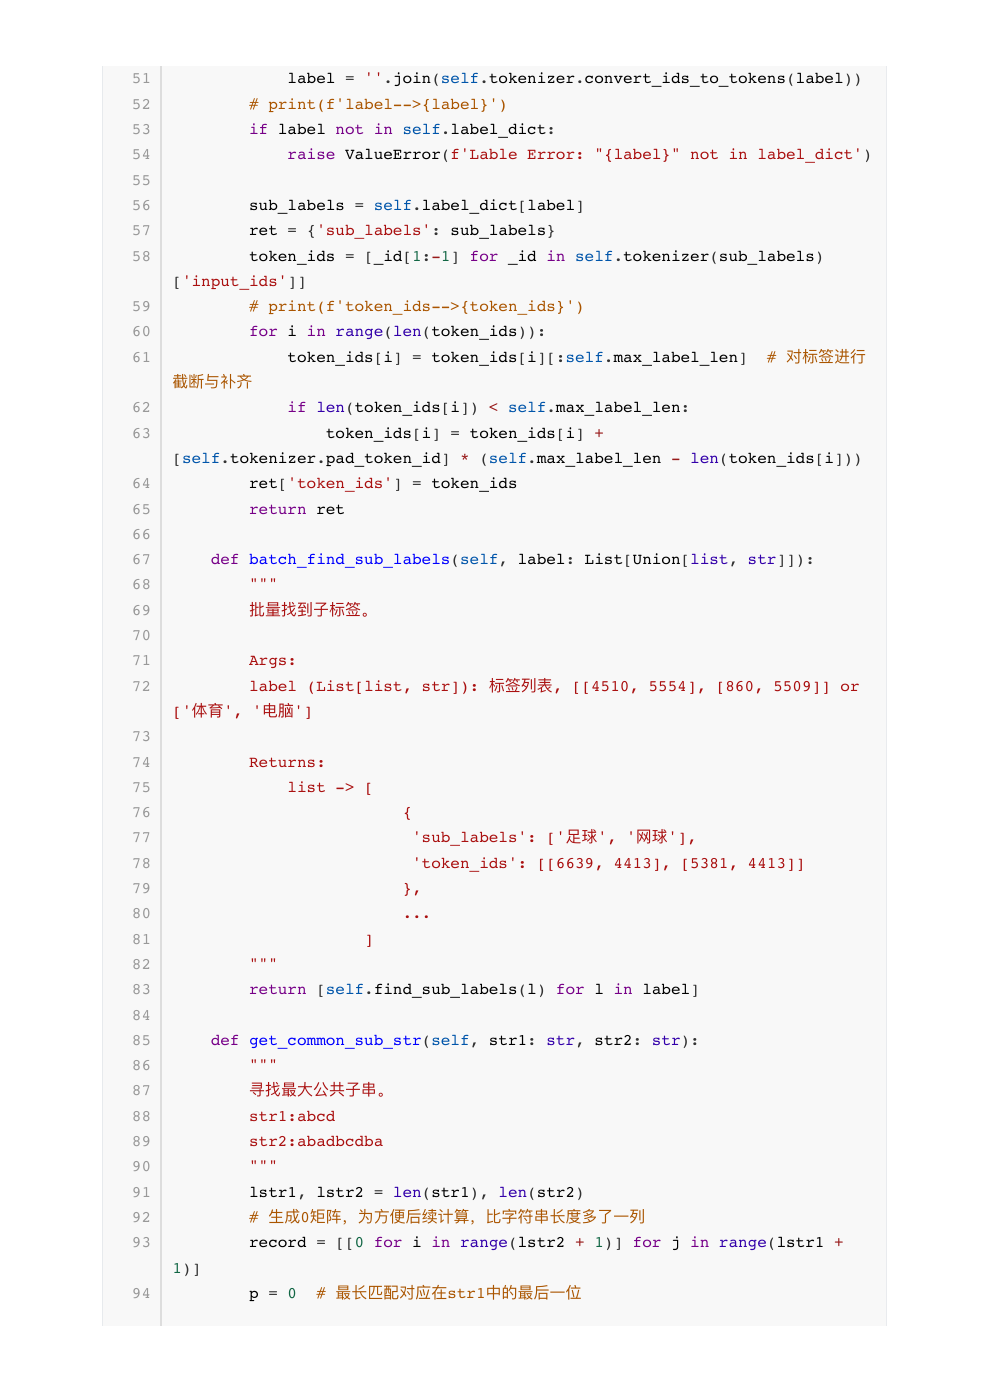

## 六、数据加载与训练输入

`data_loader.py` 使用 `load_dataset('text')` 读取 `train.txt` 和 `dev.txt`，再通过 `dataset.map()` 批量调用上一章的 `convert_example()`。最终由 `default_data_collator` 组成 DataLoader。

每个 batch 至少包含：

| 字段 | 含义 |
| --- | --- |
| `input_ids` | Prompt、原文和特殊 token 的 ID |
| `token_type_ids` | BERT 的句段标记 |
| `attention_mask` | padding 为 0，其余为 1 |
| `mask_positions` | 每个样本的 `[MASK]` 位置 |
| `mask_labels` | 原始主标签的 token ID |

训练时 `mask_labels` 先交给 Verbalizer，变成子标签 token；验证时则把它还原成主标签字符串，与模型预测的主标签比较。

```python
# coding:utf-8
from torch.utils.data import DataLoader
from transformers import default_data_collator
from data_preprocess import *
from pet_config import *

pc = ProjectConfig() # 实例化项目配置文件
tokenizer = AutoTokenizer.from_pretrained(pc.pre_model)

def get_data():
    prompt = open(pc.prompt_file, 'r', encoding='utf8').readlines()[0].strip()  # prompt定义
    # print(f'prompt--》{prompt}')
    hard_template = HardTemplate(prompt=prompt)  # 模板转换器定义
    dataset = load_dataset('text', data_files={'train': pc.train_path,
                                               'dev': pc.dev_path})
    # print(f'dataset-->{dataset}')
    # print(f'Prompt is -> {prompt}')
    new_func = partial(convert_example,
                       tokenizer=tokenizer,
                       hard_template=hard_template,
                       max_seq_len=pc.max_seq_len,
                       max_label_len=pc.max_label_len)
    # print("*"*80)
    dataset = dataset.map(new_func, batched=True)
    # print(f'dataset改变之后的-->{dataset}')
    train_dataset = dataset["train"]
    # print(f'train_dataset[0]--》{train_dataset[0]}')
    dev_dataset = dataset["dev"]
    # print(f'dev_dataset--》{dev_dataset}')
    # print('dev_dataset', dev_dataset[0])
    # print('*'*80)
    # default_data_collator作用，转换为tensor数据类型
    train_dataloader = DataLoader(train_dataset,
                                  shuffle=True,
                                  collate_fn=default_data_collator,
                                  batch_size=pc.batch_size)
    dev_dataloader = DataLoader(dev_dataset,
                                collate_fn=default_data_collator,
                                batch_size=pc.batch_size)
    return train_dataloader, dev_dataloader


if __name__ == '__main__':
    train_dataloader, dev_dataloader = get_data()
    print(len(train_dataloader))
    print(len(dev_dataloader))
    for i, value in enumerate(train_dataloader):
        print(i)
        print(value)
        print(value['input_ids'].dtype)
        break

```

### 运行前的最小数据检查

```python
from pathlib import Path

for name in ["train.txt", "dev.txt", "prompt.txt", "verbalizer.txt"]:
    p = Path("data") / name
    print(name, p.exists(), p.stat().st_size if p.exists() else 0)

print(Path("data/prompt.txt").read_text(encoding="utf-8").strip())
print(Path("data/verbalizer.txt").read_text(encoding="utf-8").splitlines())
```

训练文件必须是 `label<TAB>文本`；分隔符、编码或空行错误会在 `convert_example()` 拆分时造成异常或错位标签。

## 七、训练与验证：`train.py`

`model2train()` 的核心步骤：

1. 加载 BERT MLM 模型和 tokenizer；
2. 创建 Verbalizer；
3. 将 `bias`、`LayerNorm.weight` 从权重衰减中排除；
4. 用 AdamW 优化，并按总步数配置线性 scheduler 和 warmup；
5. 前向得到 logits，调用 `mlm_loss()` 反向传播；
6. 每 `logging_steps` 打印 loss 和速度；
7. 每 `valid_steps` 调用 `evaluate_model()`；
8. 当 F1 超过历史最好值时，保存模型与 tokenizer 到 `save_dir/model_best`。

`evaluate_model()` 会切换 `eval()`、关闭梯度、还原真实主标签、将预测子标签映射回主标签，然后计算指标，最后切回 `train()`。

```python
import os
import time
from transformers import AutoModelForMaskedLM, AutoTokenizer, get_scheduler
from utils.metirc_utils import ClassEvaluator
from utils.common_utils import *
from data_handle.data_loader import *
from utils.verbalizer import Verbalizer
from pet_config import *
from tqdm import tqdm
pc = ProjectConfig()


def evaluate_model(model, metric, data_loader, tokenizer, verbalizer):
    """
    在测试集上评估当前模型的训练效果。

    Args:
        model: 当前模型
        metric: 评估指标类(metric)
        data_loader: 测试集的dataloader
        global_step: 当前训练步数
    """
    model.eval()
    metric.reset()

    with torch.no_grad():
        for step, batch in enumerate(tqdm(data_loader)):
            # print(f'batch--》{batch}')
            logits = model(input_ids=batch['input_ids'].to(pc.device),
                           token_type_ids=batch['token_type_ids'].to(pc.device),
                           attention_mask=batch['attention_mask'].to(pc.device)).logits
            # print(f'验证集模型预测的结果————》{logits.shape}')

            mask_labels = batch['mask_labels'].numpy().tolist()  # (batch, label_num)
            # print(f"mask_labels-0-->{mask_labels}")
            for i in range(len(mask_labels)):  # 去掉label中的[PAD] token
                while tokenizer.pad_token_id in mask_labels[i]:
                    mask_labels[i].remove(tokenizer.pad_token_id)
            # print(f'mask_labels-1-->{mask_labels}')
            mask_labels = [''.join(tokenizer.convert_ids_to_tokens(t)) for t in mask_labels]  # id转文字
            # print(f'真实的结果主标签：mask_labels_str-->{mask_labels}')

            predictions = convert_logits_to_ids(logits,batch['mask_positions']).cpu().numpy().tolist()  # (batch, label_num)
            # print(f'predictions-->{predictions}')

            # print(f'模型预测的子标签的结果--》{predictions}')

            predictions = verbalizer.batch_find_main_label(predictions)  # 找到子label属于的主label
            # print(f"找到模型预测的子标签对应的主标签的结果--》{predictions}')")

            predictions = [ele['label'] for ele in predictions]
            # print(f"只获得预测的主标签的结果string--》{predictions}')")

            metric.add_batch(pred_batch=predictions, gold_batch=mask_labels)
    eval_metric = metric.compute()
    model.train()

    return eval_metric['accuracy'], eval_metric['precision'], \
           eval_metric['recall'], eval_metric['f1'], \
           eval_metric['class_metrics']


def model2train():
    # 加载预训练模型
    model = AutoModelForMaskedLM.from_pretrained(pc.pre_model)
    print(f'预训练模型带MLM头的--》{model}')
    # 加载分词器
    tokenizer = AutoTokenizer.from_pretrained(pc.pre_model)
    verbalizer = Verbalizer(verbalizer_file=pc.verbalizer,
                            tokenizer=tokenizer,
                            max_label_len=pc.max_label_len)
    print(f'verbalizer--》{verbalizer.label_dict}')

    no_decay = ["bias", "LayerNorm.weight"]
    # print(type(model.parameters()))
    optimizer_grouped_parameters = [
        {
            "params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            "weight_decay": pc.weight_decay,
        },
        {
            "params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            "weight_decay": 0.0,
        },
    ]
    optimizer = torch.optim.AdamW(optimizer_grouped_parameters, lr=pc.learning_rate)
    model.to(pc.device)

    train_dataloader, dev_dataloader = get_data()
    # # 根据训练轮数计算最大训练步数，以便于scheduler动态调整lr
    num_update_steps_per_epoch = len(train_dataloader)
    #指定总的训练步数，它会被学习率调度器用来确定学习率的变化规律，确保学习率在整个训练过程中得以合理地调节
    max_train_steps = pc.epochs * num_update_steps_per_epoch
    warm_steps = int(pc.warmup_ratio * max_train_steps) # 预热阶段的训练步数
    lr_scheduler = get_scheduler(
        name='linear',
        optimizer=optimizer,
        num_warmup_steps=warm_steps,
        num_training_steps=max_train_steps,
    )
    #
    loss_list = []
    tic_train = time.time()
    metric = ClassEvaluator()
    criterion = torch.nn.CrossEntropyLoss()
    global_step, best_f1 = 0, 0
    print('开始训练：')

    for epoch in range(pc.epochs):
        for batch in tqdm(train_dataloader):
            # print(f'batch--》{batch}')
            logits = model(input_ids=batch['input_ids'].to(pc.device),
                           token_type_ids=batch['token_type_ids'].to(pc.device),
                           attention_mask=batch['attention_mask'].to(pc.device)).logits

            # print(f'logits->{logits.shape}')
            # print('*'*80)
    #         # 真实标签
            mask_labels = batch['mask_labels'].numpy().tolist()
            # print(f'mask_labels--》{mask_labels}')
            # print(batch['mask_positions'])
            sub_labels = verbalizer.batch_find_sub_labels(mask_labels)
            # print(f'sub_labels-->{sub_labels}')
            sub_labels = [ele['token_ids'] for ele in sub_labels]
            # print(f'sub_labels-->{sub_labels}')


            loss = mlm_loss(logits,
                            batch['mask_positions'].to(pc.device),
                            sub_labels,
                            criterion,
                            pc.device,
                            )
            # print(f'计算损失值--》{loss}')

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            lr_scheduler.step()
            # loss_list.append(float(loss.cpu().detach()))
            loss_list.append(loss)
            # #
            global_step += 1

            # 打印训练日志
            if global_step % pc.logging_steps == 0:
                time_diff = time.time() - tic_train
                loss_avg = sum(loss_list) / len(loss_list)
                print("global step %d, epoch: %d, loss: %.5f, speed: %.2f step/s"
                      % (global_step, epoch, loss_avg, pc.logging_steps / time_diff))
                tic_train = time.time()
            # 模型验证
            if global_step % pc.valid_steps == 0:
                # cur_save_dir = os.path.join(pc.save_dir, "model_%d" % global_step)
                # print(f'cur_save_dir--》{cur_save_dir}')
                # if not os.path.exists(cur_save_dir):
                #     os.makedirs(cur_save_dir)
                # print(f'os.path.join(cur_save_dir)-->{os.path.join(cur_save_dir)}')
                # model.save_pretrained(os.path.join(cur_save_dir))
                # # model.save_pretrained(cur_save_dir)
                # tokenizer.save_pretrained(os.path.join(cur_save_dir))
                #
                acc, precision, recall, f1, class_metrics = evaluate_model(model,
                                                                           metric,
                                                                           dev_dataloader,
                                                                           tokenizer,
                                                                           verbalizer)

                print("Evaluation precision: %.5f, recall: %.5f, F1: %.5f" % (precision, recall, f1))
                if f1 > best_f1:
                    print(
                        f"best F1 performence has been updated: {best_f1:.5f} --> {f1:.5f}"
                    )
                    print(f'Each Class Metrics are: {class_metrics}')
                    best_f1 = f1
                    cur_save_dir = os.path.join(pc.save_dir, "model_best")
                    if not os.path.exists(cur_save_dir):
                        os.makedirs(cur_save_dir)
                    model.save_pretrained(os.path.join(cur_save_dir))
                    tokenizer.save_pretrained(os.path.join(cur_save_dir))
                tic_train = time.time()

    print('训练结束')


if __name__ == '__main__':
    model2train()

```

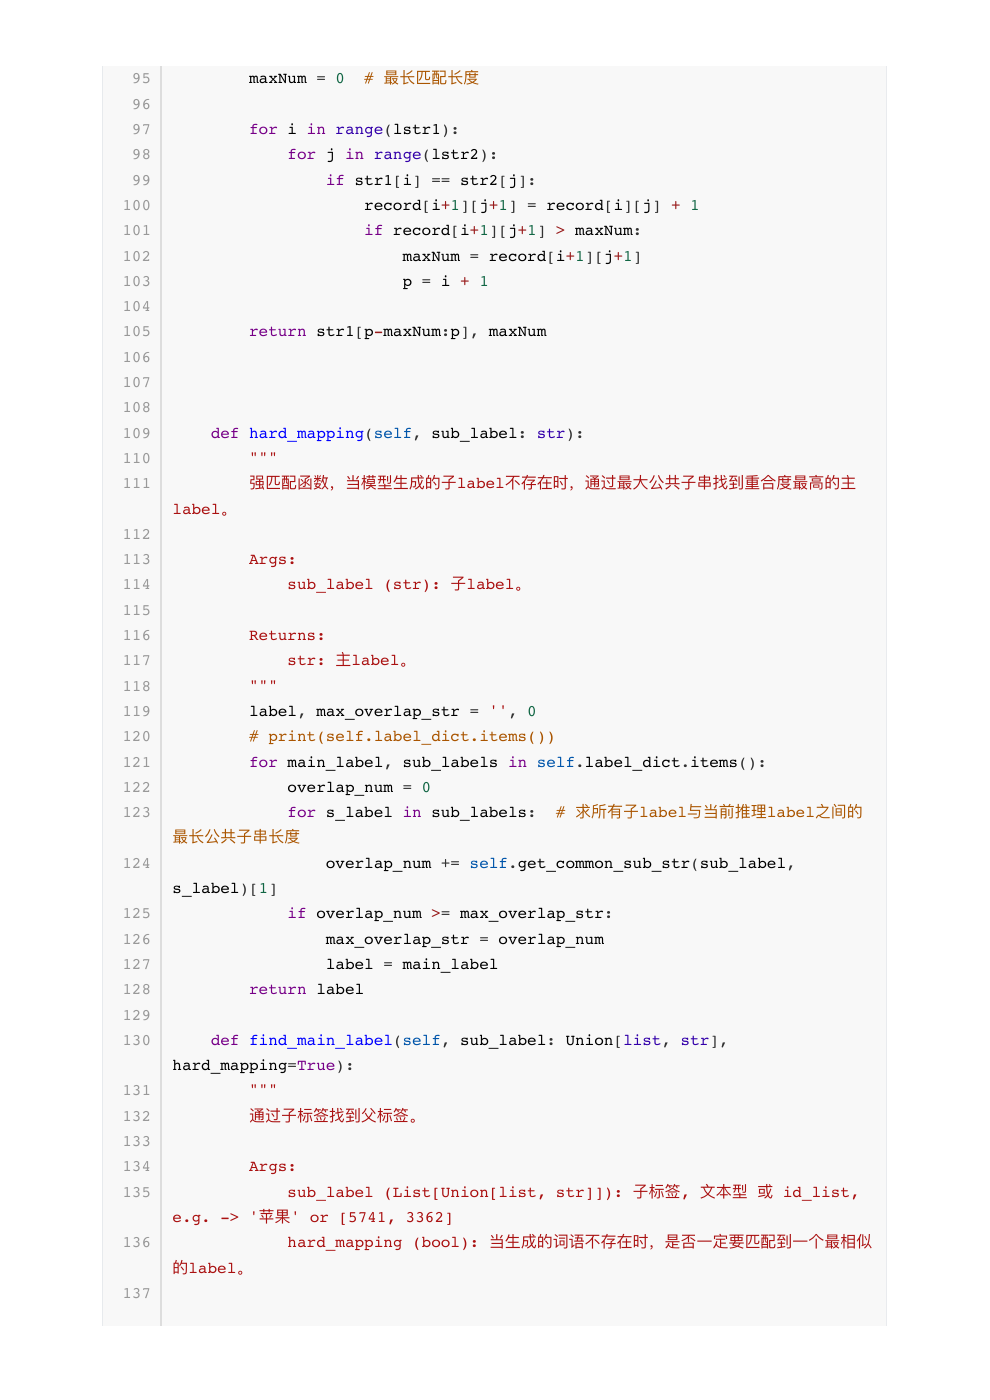

## 八、资料中的训练结果

资料的 `nohup.out` 记录了完整训练过程。一次训练在约 60 条训练样本、接近 600 条验证样本上得到：

| 验证周期 | Precision | Recall | F1 | 说明 |
| --- | ---: | ---: | ---: | --- |
| 第 2 个 epoch 左右 | 0.71 | 0.72 | 0.69 | 首次达到可用水平 |
| 第 4 个 epoch 左右 | 0.78 | 0.77 | 0.76 | 日志中较好的早期结果 |
| 后续多轮 | 约 0.78–0.79 | 约 0.76–0.77 | 约 0.75–0.76 | 指标进入平台期 |

早期日志里“手机”“电器”等类别出现过 0 召回，后续部分类别有所改善，但小样本下仍然波动明显。资料后面还记录了扩充数据后的验证结果：Precision 0.86、Recall 0.84、F1 0.85。这个对比说明增加覆盖面和类别均衡度往往比单纯增加训练轮数更有效。

注意：日志中的 epoch/global step 是当时数据量和配置下的结果；在不同设备、Transformers 版本、随机种子和数据划分下不应期待完全复现。

## 九、推理：加载 `model_best` 完成批量分类

推理代码与训练保持同一套协议：读取同一 Prompt，创建 HardTemplate，调用 `convert_example(train_mode=False)`，将输入送入保存的 `BertForMaskedLM`，再经 `convert_logits_to_ids()` 和 `Verbalizer.batch_find_main_label()` 输出主标签。

推理不能只加载 `pytorch_model.bin`：tokenizer、Prompt、Verbalizer、`max_label_len` 和模板都必须和训练时一致，否则 mask 位置或标签词空间会变化。

```python
"""
加载预训练好的模型并测试效果。

"""
import time
from typing import List

import torch
from rich import print
from transformers import AutoTokenizer, AutoModelForMaskedLM
# import sys
# sys.path.append('/Users/ligang/PycharmProjects/llm/prompt_tasks/PET/data_handle')
# sys.path.append('/Users/ligang/PycharmProjects/llm/prompt_tasks/PET/utils')
from utils.verbalizer import Verbalizer
from data_handle.template import HardTemplate
from data_handle.data_preprocess import convert_example
from utils.common_utils import convert_logits_to_ids

device = 'mps:0' # M1芯片电脑
# device = 'cuda:0' # windows--》gpu
model_path = 'checkpoints/model_best_old'
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForMaskedLM.from_pretrained(model_path)
model.to(device).eval()

max_label_len = 2                               # 标签最大长度
verbalizer = Verbalizer(
        verbalizer_file='data/verbalizer.txt',
        tokenizer=tokenizer,
        max_label_len=max_label_len
    )
prompt = open('data/prompt.txt',
                'r', encoding='utf8').readlines()[0].strip()    # prompt定义
hard_template = HardTemplate(prompt=prompt)                          # 模板转换器定义
print(f'Prompt is -> {prompt}')


def inference(contents: List[str]):
    """
    推理函数，输入原始句子，输出mask label的预测值。

    Args:
        contents (List[str]): 描原始句子列表。
    """
    with torch.no_grad():
        start_time = time.time()
        examples = {'text': contents}
        tokenized_output = convert_example(
            examples, 
            tokenizer, 
            hard_template=hard_template,
            max_seq_len=128,
            max_label_len=max_label_len,
            train_mode=False,
            return_tensor=True
        )
        # print(f'tokenized_output-->{tokenized_output}')
        logits = model(input_ids=tokenized_output['input_ids'].to(device),
                        token_type_ids=tokenized_output['token_type_ids'].to(device),
                        attention_mask=tokenized_output['attention_mask'].to(device)).logits
        predictions = convert_logits_to_ids(logits, tokenized_output['mask_positions']).cpu().numpy().tolist()  # (batch, label_num)
        predictions = verbalizer.batch_find_main_label(predictions)                                             # 找到子label属于的主label
        predictions = [ele['label'] for ele in predictions]
        used = time.time() - start_time
        print(f'Used {used}s.')
        return predictions


if __name__ == '__main__':
    contents = [
        '天台很好看，躺在躺椅上很悠闲，因为活动所以我觉得性价比还不错，适合一家出行，特别是去迪士尼也蛮近的，下次有机会肯定还会再来的，值得推荐',
        '环境，设施，很棒，周边配套设施齐全，前台小姐姐超级漂亮！酒店很赞，早餐不错，服务态度很好，前台美眉很漂亮。性价比超高的一家酒店。强烈推荐',
        "物流超快，隔天就到了，还没用，屯着出游的时候用的，听方便的，占地小",
        "福行市来到无早集市，因为是喜欢的面包店，所以跑来集市看看。第一眼就看到了，之前在微店买了小刘，这次买了老刘，还有一直喜欢的巧克力磅蛋糕。好奇老板为啥不做柠檬磅蛋糕了，微店一直都是买不到的状态。因为不爱碱水硬欧之类的，所以期待老板多来点其他小点，饼干一直也是大爱，那天好像也没看到",
        "服务很用心，房型也很舒服，小朋友很喜欢，下次去嘉定还会再选择。床铺柔软舒适，晚上休息很安逸，隔音效果不错赞，下次还会来"
    ]
    print("针对下面的文本评论，请分别给出对应所属类别：")
    res = inference(contents)
    print('inference label(s):', res)
    new_dict = {}
    for i in range(len(contents)):
        new_dict[contents[i]] = res[i]
    print(new_dict)

```

### 资料中的推理示例

讲义给了 5 条酒店、平板和水果相关评论。示例输出中，酒店环境、房型和服务评论被预测为 `酒店`，物流快、占地小的评论被预测为 `平板`，面包/甜点评论被预测为 `水果`。这类结果也体现出类别定义来自训练数据：模型学习的是数据集的业务标签，而不是通用的主题分类。

可以用下面的调用方式替换成自己的评论：

```python
from inference import inference

texts = [
    "房间很安静，早餐也不错，下次还会再来。",
    "送货很快，机身小巧，携带方便。",
]
print(inference(texts))
```

## 十、从训练到推理的建议顺序

1. 先确认本地 BERT 目录可以被 `AutoTokenizer` 和 `AutoModelForMaskedLM` 加载；
2. 检查 Prompt 中的字段名、`[MASK]` 数量和最长标签长度；
3. 先运行数据加载，打印一个 batch 的字段和形状；
4. 用很少步数跑通前向、`mlm_loss()`、反向和验证；
5. 确认 `model_best` 生成后，再运行推理；
6. 查看整体指标和每类指标，定位类别缺失、标签映射或数据不均衡问题；
7. 扩充各类别表达后再训练，不要仅依赖增加 epoch 来解决泛化问题。

常见问题：

- **设备错误**：代码默认 MPS，Windows CUDA 要改成 `cuda:0`，没有 GPU 则使用 `cpu`；
- **路径错误**：资料中的路径是作者机器的绝对路径，需要统一改成本机目录；
- **mask 对不齐**：训练和推理使用了不同 Prompt 或 `max_label_len`；
- **分类结果全是一个类**：检查训练样本分布、Verbalizer 和学习率；
- **指标异常**：确认验证集主标签和预测主标签使用同一套字符串，并查看混淆矩阵。

## 本章总结

- BERT+PET 直接复用 BERT 的 MLM 头，把文本分类转成 `[MASK]` 词预测；
- Verbalizer 连接主标签和子标签，`common_utils` 只在 mask 位置计算损失或取预测；
- `ClassEvaluator` 同时输出整体和每类指标，验证 F1 提升时保存 `model_best`；
- 推理阶段必须复用训练时的 tokenizer、Prompt、模板、Verbalizer 和标签长度配置；
- 资料结果显示，小样本训练可以快速达到约 0.76 F1，但扩大且均衡的数据覆盖能进一步提升到约 0.85 F1；
- 本篇完成了从数据 batch、模型前向、MLM loss、验证保存到批量推理的完整闭环。